In [ ]:

# ============================================================
# NLP LAB-II: TEXT FEATURES, SIMILARITY, SENTIMENT AND GENERATION
# Each section demonstrates one PPT concept with short comments.
# ============================================================

# Computers understand numbers more easily than human language.
# So, before using machine learning on text, we need to convert the text into numbers.
# Bag of Words counts how many times each word appears in a document.

print("\n--- 1. Bag of Words ---")
# Bag of Words (BoW) converts documents into word counts.
# Each row is a document; each column is a word.
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "I love machine learning",
    "Machine learning is amazing",
    "I love coding"
]
vectorizer = CountVectorizer()
bow = vectorizer.fit_transform(texts)
print("Vocabulary:", vectorizer.get_feature_names_out())
print("BoW matrix:\n", bow.toarray())


--- 1. Bag of Words ---
Vocabulary: ['amazing' 'coding' 'is' 'learning' 'love' 'machine']
BoW matrix:
 [[0 0 0 1 1 1]
 [1 0 1 1 0 1]
 [0 1 0 0 1 0]]


In [ ]:
print("\n--- 2. BoW with bigrams ---")

# A unigram is one word, a bigram is a pair of consecutive words, and a trigram is a group of three consecutive words.

# ngram_range=(2, 2) includes pairs of consecutive words.
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2))
bigram_matrix = bigram_vectorizer.fit_transform(texts)
print("Bigram vocabulary:", bigram_vectorizer.get_feature_names_out())
print("Bigram matrix:\n", bigram_matrix.toarray())


--- 2. BoW with bigrams ---
Bigram vocabulary: ['is amazing' 'learning is' 'love coding' 'love machine'
 'machine learning']
Bigram matrix:
 [[0 0 0 1 1]
 [1 1 0 0 1]
 [0 0 1 0 0]]


In [ ]:
print("\n--- 3. BoW with unigrams and bigrams ---")
# ngram_range=(1, 2) includes single words and two-word combinations.
uni_bi_vectorizer = CountVectorizer(ngram_range=(1, 2))
uni_bi_matrix = uni_bi_vectorizer.fit_transform(texts)
print("Unigrams + bigrams:", uni_bi_vectorizer.get_feature_names_out())
print("Matrix shape:", uni_bi_matrix.shape)


--- 3. BoW with unigrams and bigrams ---
Unigrams + bigrams: ['amazing' 'coding' 'is' 'is amazing' 'learning' 'learning is' 'love'
 'love coding' 'love machine' 'machine' 'machine learning']
Matrix shape: (3, 11)


In [ ]:
print("\n--- 4. TF-IDF ---")
# Term Frequency-Inverse Document Frequency

# Bag of Words counts words, but a very common word may not tell us much about a document.
# TF-IDF gives a weight to a word based on how often it occurs in a document and how common it is across the collection.

# TF-IDF weights words based on their frequency and usefulness
# across the collection of documents.
tfidf_vectorizer = TfidfVectorizer()
tfidf = tfidf_vectorizer.fit_transform(texts)
print("Vocabulary:", tfidf_vectorizer.get_feature_names_out())
print("TF-IDF matrix:\n", tfidf.toarray().round(3))


--- 4. TF-IDF ---
Vocabulary: ['amazing' 'coding' 'is' 'learning' 'love' 'machine']
TF-IDF matrix:
 [[0.    0.    0.    0.577 0.577 0.577]
 [0.563 0.    0.563 0.428 0.    0.428]
 [0.    0.796 0.    0.    0.605 0.   ]]


In [ ]:
print("\n--- 5. Jaccard similarity ---")

# Suppose two students write sentences about the same topic.
# How can we estimate how many words they have in common?
# Jaccard similarity compares the unique words in both sentences.
# Jaccard = shared unique words / all unique words in either text.
text1 = "machine learning is fun"
text2 = "learning about machine intelligence"

set1 = set(text1.split())
set2 = set(text2.split())

jaccard = len(set1 & set2) / len(set1 | set2)
print("Common words:", set1 & set2)
print("Jaccard similarity:", round(jaccard, 3))


--- 5. Jaccard similarity ---
Common words: {'machine', 'learning'}
Jaccard similarity: 0.333


In [ ]:
print("\n--- 6. Cosine similarity ---")

# Cosine similarity is another way to compare documents.
# Instead of directly comparing sets of words, we convert the documents into numerical vectors and compare the direction of those vectors.

# Cosine similarity compares numerical vectors.
# Here, TF-IDF converts text into vectors.
from sklearn.metrics.pairwise import cosine_similarity

tfidf_pair = TfidfVectorizer()
vectors = tfidf_pair.fit_transform([text1, text2])
cosine_score = cosine_similarity(vectors[0:1], vectors[1:2])[0, 0]

print("Cosine similarity:", round(float(cosine_score), 3))
print("Jaccard uses word sets; cosine uses numerical vectors.")


--- 6. Cosine similarity ---
Cosine similarity: 0.336
Jaccard uses word sets; cosine uses numerical vectors.


In [ ]:
print("\n--- 7. Sentiment analysis with TextBlob ---")

# Sentiment analysis tries to identify the opinion or emotion expressed in text.
# For example, we may want to know whether a customer review is positive, negative, or neutral.

# Polarity ranges from -1 (negative) to +1 (positive).
# Subjectivity ranges from 0 (objective) to 1 (subjective).

# Polarity: Estimates whether the text is negative or positive.
# Subjectivity: Estimates whether the text is more factual or opinion-based.

try:
    from textblob import TextBlob

    review = "The service was excellent and the staff was friendly."
    result = TextBlob(review).sentiment

    print("Review:", review)
    print("Polarity:", result.polarity)
    print("Subjectivity:", result.subjectivity)

except ImportError:
    print("Install TextBlob using: pip install textblob")


--- 7. Sentiment analysis with TextBlob ---
Review: The service was excellent and the staff was friendly.
Polarity: 0.6875
Subjectivity: 0.75



--- 8. Word cloud ---


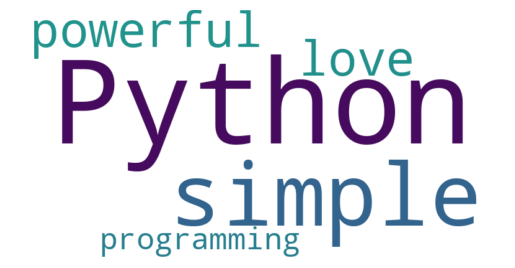

In [ ]:
print("\n--- 8. Word cloud ---")
# A word cloud is a visual representation of text. Words that occur more frequently are usually displayed in larger fonts
try:
    from wordcloud import WordCloud
    import matplotlib.pyplot as plt

    cloud_text = "Python is simple and powerful. I love Python programming!"

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(cloud_text)

    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.show()

except ImportError:
    print("Install using: pip install wordcloud matplotlib")

In [ ]:
print("\n--- 9. Machine learning, deep learning and neural networks ---")

# Machine learning allows a computer to learn patterns from examples.
# Deep learning is a type of machine learning that uses neural networks with multiple layers.

# A neuron multiplies inputs by weights, adds a bias, and normally
# passes the result through an activation function.
x = [2, 3, 1]
weights = [0.5, 0.2, 0.8]
bias = 0.1

weighted_sum = sum(
    value * weight for value, weight in zip(x, weights)
) + bias

print("Weighted sum + bias:", weighted_sum)
print("This result can be passed through an activation function.")


--- 9. Machine learning, deep learning and neural networks ---
Weighted sum + bias: 2.5000000000000004
This result can be passed through an activation function.


In [ ]:
print("\n--- 10. Text generation: tokenizer ---")

# Text generation means producing new text.
# A simple next-word prediction model learns from a training paragraph and estimates which word should come next.

# Text generation learns to predict the next word in a sequence.
# Tokenizer assigns an integer ID to each word.
# Sections 10–15 are kept inside one try block so missing TensorFlow
# does not prevent the remaining concepts from being displayed.
try:
    import numpy as np
    import tensorflow as tf

    from tensorflow.keras.preprocessing.text import Tokenizer
    from tensorflow.keras.preprocessing.sequence import pad_sequences
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Embedding, LSTM, Dense

    text = (
        "I love learning about machine learning and deep learning. "
        "Learning is fun and powerful. I love learning Python."
    )

    tokenizer = Tokenizer()
    tokenizer.fit_on_texts([text])

    print("Word index:", tokenizer.word_index)


    print("\n--- 11. Create input sequences ---")
    # Each growing sequence provides an example for predicting the next word.
    token_ids = tokenizer.texts_to_sequences([text])[0]

    sequences = []
    for i in range(2, len(token_ids) + 1):
        sequences.append(token_ids[:i])

    print("First few sequences:", sequences[:5])


    print("\n--- 12. Pad sequences ---")
    # Padding makes every sequence the same length.
    max_len = max(len(seq) for seq in sequences)

    padded = pad_sequences(
        sequences,
        maxlen=max_len,
        padding="pre"
    )

    print("Padded sequence array:\n", padded[:5])


    print("\n--- 13. Split X and y; one-hot encode y (PPT) ---")
    # X contains earlier words; y contains the next word to predict.
    # One-hot encoding represents the target word with a vector containing 1.
    sequences_array = np.array(padded)

    X = sequences_array[:, :-1]
    y_ids = sequences_array[:, -1]

    vocab_size = len(tokenizer.word_index) + 1

    y = tf.keras.utils.to_categorical(
        y_ids,
        num_classes=vocab_size
    )

    print("X shape:", X.shape)
    print("y shape after one-hot encoding:", y.shape)


    print("\n--- 14. Build and train an LSTM model ---")
    # Embedding learns word vectors.
    # LSTM learns sequence patterns.
    # Dense + softmax predicts the next word.
    model = Sequential([
        Embedding(vocab_size, 10),
        LSTM(32),
        Dense(vocab_size, activation="softmax")
    ])

    model.compile(
        loss="categorical_crossentropy",
        optimizer="adam",
        metrics=["accuracy"]
    )

    # A small number of epochs keeps the classroom demonstration manageable.
    model.fit(X, y, epochs=100, verbose=0)

    print("Model training complete.")


    print("\n--- 15. Generate new text ---")
    # Start with a seed phrase, predict a word, and append it repeatedly.
    def generate_text(seed_text, next_words=3):
        for _ in range(next_words):
            token_list = tokenizer.texts_to_sequences([seed_text])[0]

            # The input length must match the model's training input length.
            token_list = pad_sequences(
                [token_list],
                maxlen=X.shape[1],
                padding="pre"
            )

            predicted = model.predict(token_list, verbose=0)[0]
            predicted_id = int(np.argmax(predicted))
            predicted_word = tokenizer.index_word.get(predicted_id, "")

            if not predicted_word:
                break

            seed_text += " " + predicted_word

        return seed_text

    print("Generated text:", generate_text("machine", next_words=3))

except ImportError as error:
    print("\nTensorFlow or a required package is missing.")
    print("Install using: pip install tensorflow")
    print("Details:", error)


--- 10. Text generation: tokenizer ---
Word index: {'learning': 1, 'i': 2, 'love': 3, 'and': 4, 'about': 5, 'machine': 6, 'deep': 7, 'is': 8, 'fun': 9, 'powerful': 10, 'python': 11}

--- 11. Create input sequences (PPT) ---
First few sequences: [[2, 3], [2, 3, 1], [2, 3, 1, 5], [2, 3, 1, 5, 6], [2, 3, 1, 5, 6, 1]]

--- 12. Pad sequences (PPT) ---
Padded sequence array:
 [[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 3]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 3 1]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 3 1 5]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 2 3 1 5 6]
 [0 0 0 0 0 0 0 0 0 0 0 0 2 3 1 5 6 1]]

--- 13. Split X and y; one-hot encode y (PPT) ---
X shape: (17, 17)
y shape after one-hot encoding: (17, 12)

--- 14. Build and train an LSTM model (PPT) ---
Model training complete.

--- 15. Generate new text (PPT) ---
Generated text: machine learning learning learning


The assignment starts from here.

In [ ]:
#q1
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from collections import FreqDist

nltk.download('punkt')
nltk.download('stopwords')

text = "Cloud computing revolutionizes how we deploy applications. Amazon Web Services provides scalable infrastructure like EC2 instances and S3 buckets! Developers love building full-stack dashboards using React and FastAPI. Efficient database management ensures seamless data retrieval. Ultimately, cloud platforms accelerate modern software engineering."

text_lower = text.lower()
text_clean = re.sub(r'[^\w\s]', '', text_lower)

sentences = sent_tokenize(text)
words_nltk = word_tokenize(text_clean)
words_split = text_clean.split()

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words_nltk if word not in stop_words]

freq_dist = FreqDist(filtered_words)
print(freq_dist.most_common())

In [ ]:
#q2
from nltk.stem import PorterStemmer, WordNetLemmatizer
nltk.download('wordnet')

alpha_words = re.findall(r'\b[a-z]+\b', text.lower())
filtered_alpha = [w for w in alpha_words if w not in stop_words]

stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in filtered_alpha]

lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(w) for w in filtered_alpha]

print("Stemmed:", stemmed_words)
print("Lemmatized:", lemmatized_words)

In [ ]:
#q3
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import numpy as np

texts = [
    "AWS S3 buckets provide excellent static website hosting.",
    "Dynamic programming and graph algorithms are crucial for competitive programming.",
    "FastAPI and Pandas optimize backend data processing efficiently."
]

vectorizer = CountVectorizer()
bow_matrix = vectorizer.fit_transform(texts)
print(vectorizer.get_feature_names_out())

tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)
feature_names = np.array(tfidf_vectorizer.get_feature_names_out())

for i, doc in enumerate(tfidf_matrix.toarray()):
    top_indices = np.argsort(doc)[-3:][::-1]
    print(f"Text {i+1} Top Keywords:", feature_names[top_indices])

In [ ]:
#q4
from sklearn.metrics.pairwise import cosine_similarity

text_ai = "Conversational AI uses natural language processing to understand user intent. It requires heavy neural network architectures."
text_cloud = "Cloud backup platforms ensure disaster recovery by replicating data. AWS EC2 and S3 are essential for cloud infrastructure."

def preprocess(t):
    return set([w for w in word_tokenize(re.sub(r'[^\w\s]', '', t.lower())) if w not in stop_words])

set_ai = preprocess(text_ai)
set_cloud = preprocess(text_cloud)

jaccard = len(set_ai & set_cloud) / len(set_ai | set_cloud)
print("Jaccard Similarity:", round(jaccard, 3))

vectors = tfidf_vectorizer.fit_transform([text_ai, text_cloud])
cosine_score = cosine_similarity(vectors[0:1], vectors[1:2])[0, 0]
print("Cosine Similarity:", round(float(cosine_score), 3))

In [ ]:
#q5
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
"The new IDE integration is absolutely amazing and speeds up my workflow significantly.",
"The database migration was a complete disaster and caused terrible downtime.",
"The software update includes minor changes to the user interface."
]

positive_text = ""

for review in reviews:
    result = TextBlob(review).sentiment
    pol, subj = result.polarity, result.subjectivity

    if pol > 0.1:
        sentiment = "Positive"
        positive_text += review + " "
    elif pol < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

print(f"Polarity: {pol:.2f} | Subjectivity: {subj:.2f} | Class: {sentiment}")

wordcloud = WordCloud(width=800, height=400, background_color="white").generate(positive_text)
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

In [ ]:
#q6
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

training_text = """
Developing an automated audit system requires analyzing pull request data effectively.
By utilizing Python frameworks, software engineers can parse GitHub API responses to detect anomalies in review efforts.
The system flags unexpected code commits, ensuring high quality control during peer reviews.
Building the frontend with React allows team members to visualize these anomalies on an interactive dashboard.
Simultaneously, the backend processes incoming datasets using efficient matrix operations and data structures.
This continuous integration loop secures the main branch from unverified modifications, creating a robust, reliable, and highly scalable software lifecycle.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
vocab_size = len(tokenizer.word_index) + 1

token_ids = tokenizer.texts_to_sequences([training_text])[0]
sequences = [token_ids[:i] for i in range(2, len(token_ids) + 1)]
max_len = max(len(seq) for seq in sequences)
padded = pad_sequences(sequences, maxlen=max_len, padding="pre")

X = padded[:, :-1]
y_ids = padded[:, -1]
y = tf.keras.utils.to_categorical(y_ids, num_classes=vocab_size)

model = Sequential([
    Embedding(vocab_size, 10),
    LSTM(32),
    Dense(vocab_size, activation="softmax")
])
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

model.fit(X, y, epochs=100, verbose=0)

def generate_text(seed_text, next_words=15):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences([token_list], maxlen=X.shape[1], padding="pre")
        predicted = model.predict(token_list, verbose=0)[0]
        predicted_id = int(np.argmax(predicted))
        predicted_word = tokenizer.index_word.get(predicted_id, "")

        if not predicted_word:
            break

        seed_text += " " + predicted_word

    return seed_text

print(generate_text("Developing an automated", next_words=15))